# PreventIA — Clasificación de daños con una MLP

## 1. Lectura del dataset

In [16]:
from pathlib import Path
import xml.etree.ElementTree as ET
import hashlib
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

CLASES = {'D00': 'Grieta longitudinal', 'D10': 'Grieta transversal',
          'D20': 'Grieta tipo cocodrilo', 'D40': 'Bache'}
DATOS = Path.cwd() / 'United_States'
if not (DATOS / 'train').is_dir():
    DATOS = DATOS / 'United_States'
if not (DATOS / 'train' / 'annotations' / 'xmls').is_dir():
    raise FileNotFoundError('Coloca United_States junto al notebook o corrige DATOS.')

In [17]:
fotos_train = sorted(p for p in (DATOS / 'train' / 'images').iterdir()
                     if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
xmls = sorted((DATOS / 'train' / 'annotations' / 'xmls').glob('*.xml'))
fotos_test = sorted(p for p in (DATOS / 'test' / 'images').glob('*')
                    if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
sin_xml = {p.stem for p in fotos_train} - {p.stem for p in xmls}
sin_foto = {p.stem for p in xmls} - {p.stem for p in fotos_train}
print('Fotografías de train:', len(fotos_train))
print('Anotaciones XML:', len(xmls))
print('Fotografías de test:', len(fotos_test))
print('Fotografías sin XML:', len(sin_xml), '| XML sin fotografía:', len(sin_foto))
if sin_xml or sin_foto or not xmls:
    raise ValueError('Revisa la correspondencia de las imágenes y los XML.')

ejemplo_xml = ET.parse(xmls[0]).getroot()
print('Ejemplo de XML:', xmls[0].name)
for objeto in ejemplo_xml.findall('object'):
    clase = objeto.findtext('name')
    coordenadas = [objeto.findtext(f'bndbox/{k}') for k in ('xmin', 'ymin', 'xmax', 'ymax')]
    print('Daño:', clase, '| Rectángulo:', coordenadas)

Fotografías de train: 4805
Anotaciones XML: 4805
Fotografías de test: 1200
Fotografías sin XML: 0 | XML sin fotografía: 0
Ejemplo de XML: United_States_000000.xml
Daño: D10 | Rectángulo: ['556', '510', '640', '544']
Daño: D10 | Rectángulo: ['502', '458', '624', '494']
Daño: D00 | Rectángulo: ['579', '552', '633', '615']


## 2. Preprocesamiento de las imágene

In [18]:
def preparar_recorte(imagen):
    gris = imagen.convert('L').resize((32, 32), Image.Resampling.BILINEAR)
    return np.asarray(gris, dtype=np.float32).reshape(-1) / 255.0

X, y, grupos, ejemplos = [], [], [], []
for archivo in xmls:
    anotacion = ET.parse(archivo).getroot()
    ruta = DATOS / 'train' / 'images' / anotacion.findtext('filename')
    with Image.open(ruta) as original:
        imagen = original.convert('RGB')
        grupo = hashlib.sha256(imagen.tobytes()).hexdigest()
        for objeto in anotacion.findall('object'):
            clase = objeto.findtext('name')
            if clase not in CLASES:
                raise ValueError(f'Clase desconocida en {archivo.name}: {clase}')
            caja = tuple(int(objeto.findtext(f'bndbox/{k}'))
                         for k in ('xmin', 'ymin', 'xmax', 'ymax'))
            x1, y1, x2, y2 = caja
            if not (0 <= x1 < x2 <= imagen.width and 0 <= y1 < y2 <= imagen.height):
                raise ValueError(f'Revisa las coordenadas en {archivo.name}')
            X.append(preparar_recorte(imagen.crop(caja)))
            y.append(clase)
            grupos.append(grupo)
            ejemplos.append((ruta, caja))

X, y, grupos = np.array(X), np.array(y), np.array(grupos)
print('Total de recortes preparados:', len(y))
print('Entradas por recorte:', X.shape[1])
print('Valores de píxel:', float(X.min()), 'a', float(X.max()))
print('Daños anotados por clase:')
for clase, nombre in CLASES.items():
    print(f'  {clase} — {nombre}: {int(np.sum(y == clase))}')

Total de recortes preparados: 11014
Entradas por recorte: 1024
Valores de píxel: 0.0 a 1.0
Daños anotados por clase:
  D00 — Grieta longitudinal: 6750
  D10 — Grieta transversal: 3295
  D20 — Grieta tipo cocodrilo: 834
  D40 — Bache: 135


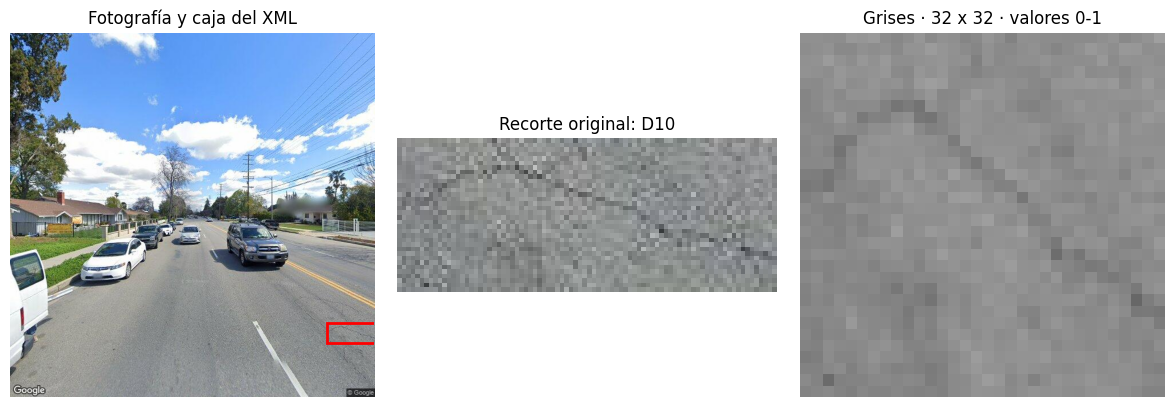

In [19]:
from matplotlib.patches import Rectangle
ruta, caja = ejemplos[0]
with Image.open(ruta) as archivo:
    foto_ejemplo = archivo.convert('RGB')
x1, y1, x2, y2 = caja
fig, ejes = plt.subplots(1, 3, figsize=(12, 4))
ejes[0].imshow(foto_ejemplo)
ejes[0].add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color='red', linewidth=2))
ejes[0].set_title('Fotografía y caja del XML')
ejes[1].imshow(foto_ejemplo.crop(caja))
ejes[1].set_title(f'Recorte original: {y[0]}')
ejes[2].imshow(X[0].reshape(32, 32), cmap='gray', vmin=0, vmax=1)
ejes[2].set_title('Grises · 32 x 32 · valores 0-1')
for eje in ejes:
    eje.axis('off')
plt.tight_layout()
plt.show()

## 3. Separar entrenamiento y validación
Reservamos aproximadamente el **80 % para entrenar y el 20 % para validar**.
Los recortes de una foto y las fotos idénticas permanecen en el mismo grupo.
La semilla 42 permite repetir la división. Ambos conjuntos salen de `train`.
La proporción de recortes puede variar, porque cada foto contiene una cantidad diferente de daños.

In [20]:
g_train, g_val = train_test_split(np.unique(grupos), test_size=0.2, random_state=42)
es_train = np.isin(grupos, g_train)
X_train, X_val = X[es_train], X[~es_train]
y_train, y_val = y[es_train], y[~es_train]
ejemplos_val = [ejemplos[i] for i in np.flatnonzero(~es_train)]
print('Recortes para entrenar:', len(y_train))
print('Recortes para validar:', len(y_val))
print('Entradas por recorte:', X.shape[1])

Recortes para entrenar: 8745
Recortes para validar: 2269
Entradas por recorte: 1024


## 4. Entrenar y comprobar la MLP

In [21]:
modelo = MLPClassifier(hidden_layer_sizes=(32,), activation='relu',
                       solver='adam', alpha=0.01, max_iter=300, random_state=42)
modelo.fit(X_train, y_train)
print('Entrenamiento terminado.')

Entrenamiento terminado.


In [22]:
predicciones = modelo.predict(X_val)
aciertos = int(np.sum(predicciones == y_val))
print(f'Aciertos: {aciertos} de {len(y_val)}')
print(f'Porcentaje de aciertos: {aciertos / len(y_val):.2%}')

Aciertos: 1679 de 2269
Porcentaje de aciertos: 74.00%


## 5. Probar un ejemplo conocido

Predicción: D00 — Grieta longitudinal
Etiqueta real: D00 — Grieta longitudinal


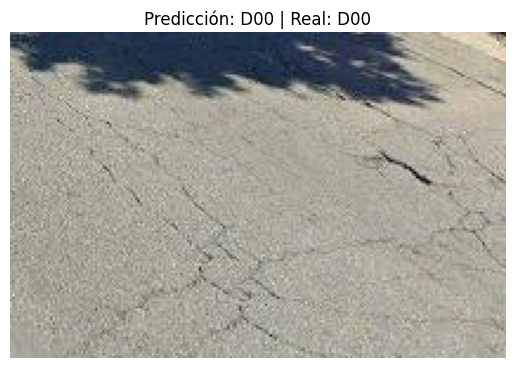

In [23]:
numero = 0
if not 0 <= numero < len(X_val):
    raise ValueError(f'Elige un número entre 0 y {len(X_val) - 1}.')
clase = str(modelo.predict(X_val[numero:numero + 1])[0])
print('Predicción:', clase, '—', CLASES[clase])
print('Etiqueta real:', y_val[numero], '—', CLASES[y_val[numero]])
ruta, caja = ejemplos_val[numero]
with Image.open(ruta) as foto:
    plt.imshow(foto.convert('RGB').crop(caja))
plt.title(f'Predicción: {clase} | Real: {y_val[numero]}')
plt.axis('off')
plt.show()

## 6. Abrir una fotografía y marcar daños

In [24]:
import tkinter as tk
from tkinter import filedialog
from PIL import ImageTk

def abrir_y_marcar():
    ventana = tk.Tk()
    ventana.title('PreventIA — Seleccionar fotografía')
    ventana.update()
    ruta = filedialog.askopenfilename(parent=ventana, title='Selecciona una fotografía',
        initialdir=str(DATOS / 'test' / 'images'), filetypes=[('Imágenes', '*.jpg *.jpeg *.png')])
    if not ruta:
        ventana.destroy()
        return None
    try:
        with Image.open(ruta) as archivo:
            foto = archivo.convert('RGB')
    except OSError:
        ventana.destroy()
        raise ValueError('No se pudo abrir la fotografía.')
    vista = foto.copy()
    vista.thumbnail((min(900, ventana.winfo_screenwidth() - 100),
                     min(650, ventana.winfo_screenheight() - 200)))
    ventana.title('PreventIA — Arrastra para marcar un daño')
    ventana.deiconify()
    lienzo = tk.Canvas(ventana, width=vista.width, height=vista.height, highlightthickness=0)
    lienzo.pack()
    imagen_tk = ImageTk.PhotoImage(vista, master=ventana)
    lienzo.create_image(0, 0, image=imagen_tk, anchor='nw')
    mensaje = tk.Label(ventana, text='Marca una o varias regiones que contengan daños.')
    mensaje.pack()
    resultados, inicio = [], []
    rectangulo = None

    def empezar(evento):
        nonlocal rectangulo
        inicio[:] = [evento.x, evento.y]
        rectangulo = lienzo.create_rectangle(*inicio, *inicio, outline='red', width=2, tags='seleccion')

    def mover(evento):
        if inicio:
            x = min(max(evento.x, 0), vista.width)
            y = min(max(evento.y, 0), vista.height)
            lienzo.coords(rectangulo, *inicio, x, y)

    def clasificar(evento):
        if not inicio:
            return
        mover(evento)
        x1, y1, x2, y2 = lienzo.coords(rectangulo)
        inicio.clear()
        if abs(x2 - x1) < 5 or abs(y2 - y1) < 5:
            lienzo.delete(rectangulo)
            mensaje.config(text='Marca un rectángulo de al menos 5 píxeles por lado.')
            return
        caja = (round(min(x1, x2) * foto.width / vista.width),
                round(min(y1, y2) * foto.height / vista.height),
                round(max(x1, x2) * foto.width / vista.width),
                round(max(y1, y2) * foto.height / vista.height))
        entrada = preparar_recorte(foto.crop(caja)).reshape(1, -1)
        clase = str(modelo.predict(entrada)[0])
        resultados.append((caja, clase))
        etiqueta = f'{len(resultados)}: {clase}'
        lienzo.create_text(min(x1, x2) + 3, min(y1, y2) + 3, text=etiqueta,
                           anchor='nw', fill='red', font=('Arial', 12, 'bold'), tags='seleccion')
        mensaje.config(text=f'Región {len(resultados)}: {CLASES[clase]}')

    def borrar():
        resultados.clear()
        inicio.clear()
        lienzo.delete('seleccion')
        mensaje.config(text='Selecciones borradas. Marca una región dañada.')

    lienzo.bind('<Button-1>', empezar)
    lienzo.bind('<B1-Motion>', mover)
    lienzo.bind('<ButtonRelease-1>', clasificar)
    tk.Button(ventana, text='Borrar selecciones', command=borrar).pack(side='left', padx=12, pady=8)
    tk.Button(ventana, text='Terminar', command=ventana.destroy).pack(side='right', padx=12, pady=8)
    ventana.mainloop()
    return foto, resultados

Región 1: D00 — Grieta longitudinal
Región 2: D00 — Grieta longitudinal
Región 3: D10 — Grieta transversal


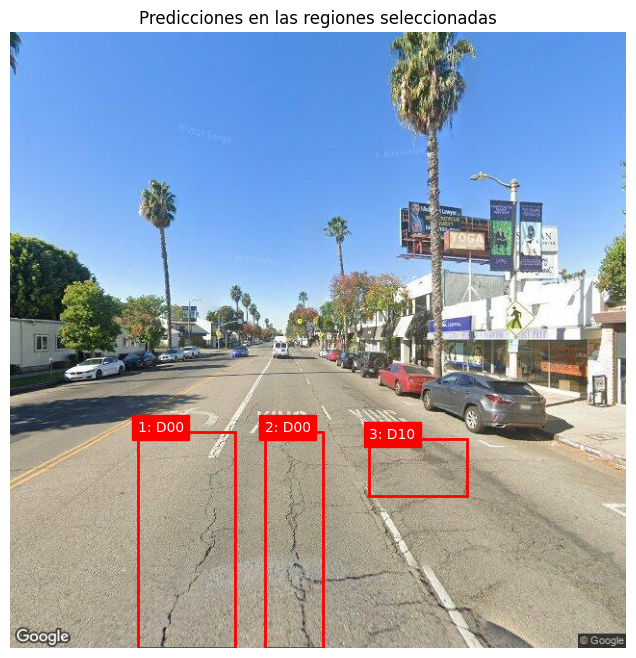

In [12]:
seleccion = abrir_y_marcar()
if seleccion and seleccion[1]:
    foto, resultados = seleccion
    fig, eje = plt.subplots(figsize=(8, 8))
    eje.imshow(foto)
    for numero, (caja, clase) in enumerate(resultados, 1):
        x1, y1, x2, y2 = caja
        eje.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color='red', linewidth=2))
        eje.text(x1, y1, f'{numero}: {clase}', color='white', backgroundcolor='red')
        print(f'Región {numero}: {clase} — {CLASES[clase]}')
    eje.set_title('Predicciones en las regiones seleccionadas')
    eje.axis('off')
    plt.show()
else:
    print('No se seleccionaron regiones.')